# Title : Analyzing Weather Data from OpenWeatherMap API

In [11]:
import requests 
import pandas as pd 
import datetime

In [12]:
# Set your OpenWeatherMap API key
api_key = '63dcaa2eacb822ec94795bfcd3c9caa4' 

In [13]:
# Set the location for which you want to retrieve weather data 
lat = 18.184135
lon = 74.610764

In [14]:
# Construct the API URL
api_url = "https://api.openweathermap.org/data/2.5/forecast"

params = {
    "lat": lat,
    "lon": lon,
    "appid": api_key,
    "units": "metric"
}

In [15]:
# Send GET request
response = requests.get(api_url, params=params)

# Check API response
print("Status Code:", response.status_code)

# Convert JSON response into dictionary
weather_data = response.json()

# Check whether request was successful
if response.status_code == 200:

    print("API Connected Successfully!")

    print("Available Keys:", weather_data.keys())

    print("Number of Forecast Records:", len(weather_data['list']))

    print("Weather Description:",
          weather_data['list'][0]['weather'][0]['description'])

else:
    print("API Error:", weather_data)

Status Code: 200
API Connected Successfully!
Available Keys: dict_keys(['cod', 'message', 'cnt', 'list', 'city'])
Number of Forecast Records: 40
Weather Description: scattered clouds


In [16]:
# Extract weather attributes

timestamps = [
    pd.to_datetime(item['dt'], unit='s')
    for item in weather_data['list']
]

temperatures = [
    item['main']['temp']
    for item in weather_data['list']
]

humidity = [
    item['main']['humidity']
    for item in weather_data['list']
]

wind_speed = [
    item['wind']['speed']
    for item in weather_data['list']
]

weather_description = [
    item['weather'][0]['description']
    for item in weather_data['list']
]

precipitation = [
    item.get('rain', {}).get('3h', 0)
    for item in weather_data['list']
]

In [17]:
# Create a pandas DataFrame with the extracted weather data
weather_df = pd.DataFrame({'Timestamp': timestamps, 
                           'Temperature': temperatures, 
                           'humidity': humidity, 
                           'wind_speed':wind_speed,
                           'weather_description': weather_description})

In [18]:
# Set the Timestamp column as the DataFrame's index
weather_df.set_index('Timestamp', inplace=True)
max_temp = weather_df['Temperature'].max()
print(f"Maximum Temperature - {max_temp}")
min_temp = weather_df['Temperature'].min()
print(f"Minimum Temperature - {min_temp}")

Maximum Temperature - 30.31
Minimum Temperature - 16.75


In [19]:
# Clean and preprocess the data # Handling missing values
weather_df.fillna(0, inplace=True) # Replace missing values with 0 or appropriate value

In [20]:
# Handling inconsistent format (if applicable)
weather_df['Temperature'] = weather_df['Temperature'].apply(lambda x: x - 273.15 if isinstance(x, float)else x)

In [21]:
# Convert temperature from Kelvin to Celsius
# Print the cleaned and preprocessed data print(weather_df)
print(weather_df)

                     Temperature  humidity  wind_speed weather_description
Timestamp                                                                 
2026-11-15 18:00:00      -250.86        33        2.80    scattered clouds
2026-11-15 21:00:00      -252.33        37        2.41       broken clouds
2026-11-16 00:00:00      -254.65        47        1.10     overcast clouds
2026-11-16 03:00:00      -250.49        37        1.43       broken clouds
2026-11-16 06:00:00      -244.91        27        1.58       broken clouds
2026-11-16 09:00:00      -243.07        23        1.00     overcast clouds
2026-11-16 12:00:00      -246.52        33        1.27     overcast clouds
2026-11-16 15:00:00      -249.91        34        1.76    scattered clouds
2026-11-16 18:00:00      -250.85        37        2.92       broken clouds
2026-11-16 21:00:00      -252.87        43        1.82       broken clouds
2026-11-17 00:00:00      -254.09        45        1.86    scattered clouds
2026-11-17 03:00:00      

In [22]:
import matplotlib.pyplot as plt
daily_mean_temp = weather_df['Temperature'].resample('D').mean()
daily_mean_humidity = weather_df['humidity'].resample('D').mean()
daily_mean_wind_speed = weather_df['wind_speed'].resample('D').mean()

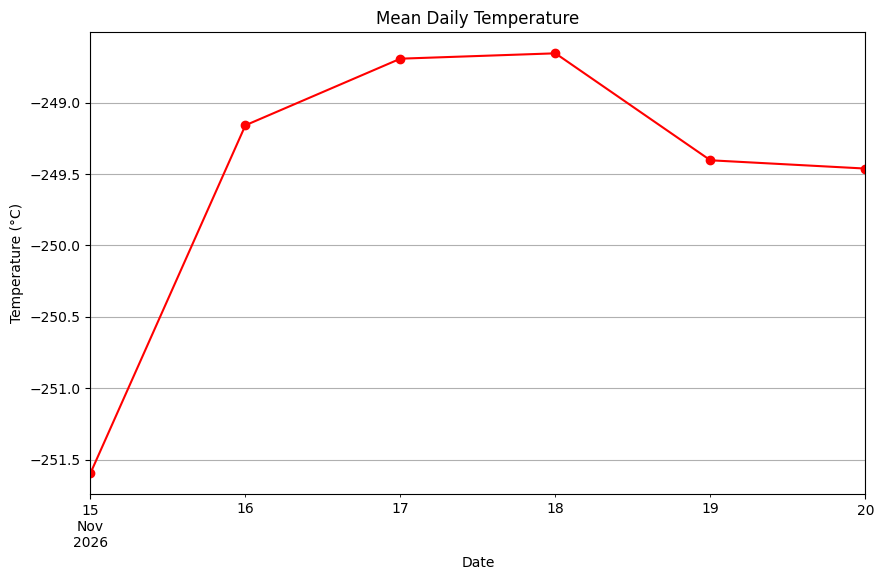

In [23]:
# Plot the mean daily temperature over time (Line plot)
plt.figure(figsize=(10, 6))
daily_mean_temp.plot(color='red', linestyle='-', marker='o')
plt.title('Mean Daily Temperature')
plt.xlabel('Date')
plt.ylabel('Temperature (°C)')
plt.grid(True)
plt.show()

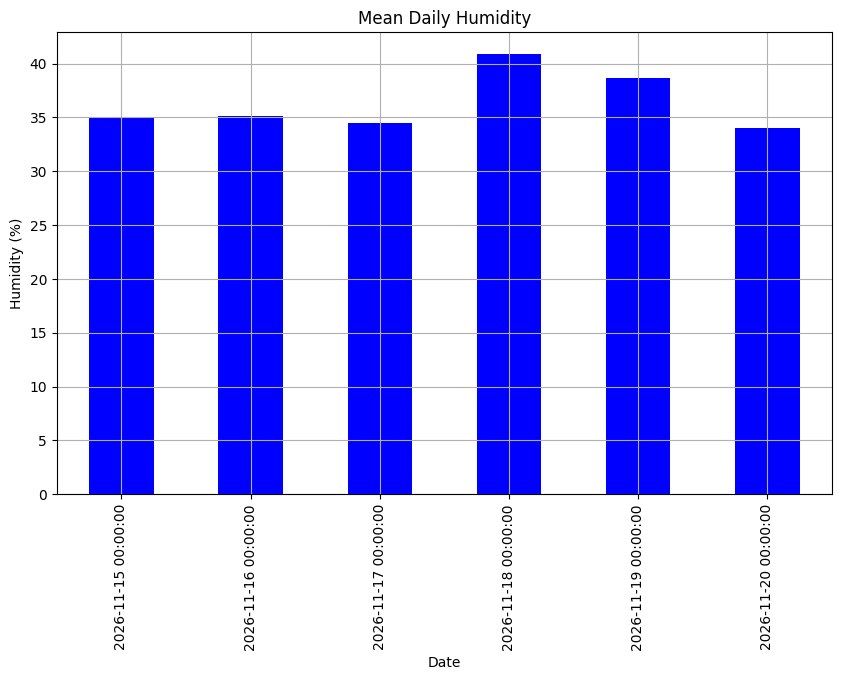

In [24]:
# Plot the mean daily humidity over time (Bar plot)
plt.figure(figsize=(10, 6))
daily_mean_humidity.plot(kind='bar', color='blue')
plt.title('Mean Daily Humidity')
plt.xlabel('Date')
plt.ylabel('Humidity (%)')
plt.grid(True)
plt.show()

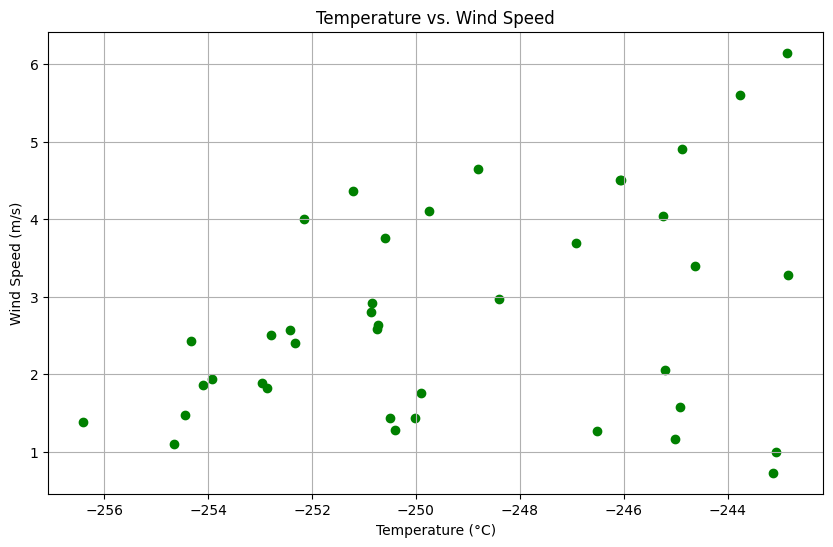

In [25]:
# Plot the relationship between temperature and wind speed (Scatter plot)
plt.figure(figsize=(10, 6))
plt.scatter(weather_df['Temperature'], weather_df['wind_speed'], color='green')
plt.title('Temperature vs. Wind Speed')
plt.xlabel('Temperature (°C)')
plt.ylabel('Wind Speed (m/s)')
plt.grid(True)
plt.show()

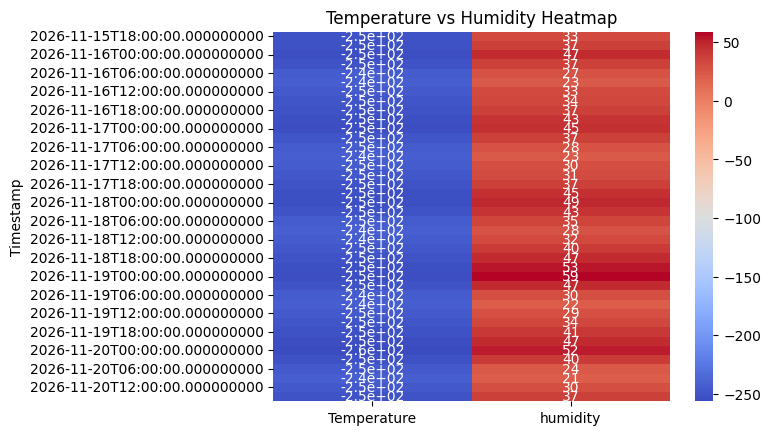

In [26]:
# Heatmap
import seaborn as sns
heatmap_data = weather_df[['Temperature', 'humidity']]
sns.heatmap(heatmap_data, annot=True, cmap='coolwarm')
plt.title('Temperature vs Humidity Heatmap')
plt.show()

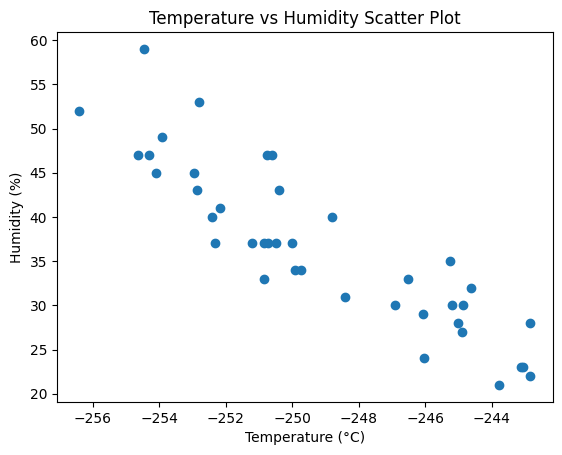

In [27]:
# Create a scatter plot to visualize the relationship between temperature and humidity
plt.scatter(weather_df['Temperature'], weather_df['humidity'])
plt.xlabel('Temperature (°C)')
plt.ylabel('Humidity (%)')
plt.title('Temperature vs Humidity Scatter Plot')
plt.show()